# GEC-RAG Project
## Notebook 01 — Data Exploration & Corpus Analysis
**Write & Improve Corpus 2024**

This notebook loads and explores the Write & Improve Corpus 2024, including:
- Corpus metadata and CEFR distribution
- Sentence-level parallel pairs (original vs corrected)
- Pre-annotated ERRANT error type statistics

These statistics will be reported in the paper's dataset section.

---
### Cell 1 — Imports

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Install any missing packages
import subprocess, sys
for pkg in ['matplotlib', 'seaborn']:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

print('✅ Imports successful')

✅ Imports successful


---
### Cell 2 — Define Paths

In [2]:
# Base paths
BASE_DIR = 'C:/gecrag'
DATA_DIR = os.path.join(BASE_DIR, 'data/write_and_improve')

# Subdirectory paths
WHOLE_CORPUS_DIR    = os.path.join(DATA_DIR, 'whole-corpus')
FINAL_VERSIONS_DIR  = os.path.join(DATA_DIR, 'user-prompt-final-versions')
MULTIGEC_DIR        = os.path.join(DATA_DIR, 'multigec-2025-files')
RESULTS_DIR         = os.path.join(BASE_DIR, 'results')

# Create results directory if it doesn't exist
os.makedirs(RESULTS_DIR, exist_ok=True)

# Verify all paths exist
for name, path in [
    ('Base Data Dir',   DATA_DIR),
    ('Whole Corpus',    WHOLE_CORPUS_DIR),
    ('Final Versions',  FINAL_VERSIONS_DIR),
    ('MultiGEC',        MULTIGEC_DIR),
    ('Results',         RESULTS_DIR),
]:
    status = '✅' if os.path.exists(path) else '❌'
    print(f'{status} {name}: {path}')

✅ Base Data Dir: C:/gecrag\data/write_and_improve
✅ Whole Corpus: C:/gecrag\data/write_and_improve\whole-corpus
✅ Final Versions: C:/gecrag\data/write_and_improve\user-prompt-final-versions
✅ MultiGEC: C:/gecrag\data/write_and_improve\multigec-2025-files
✅ Results: C:/gecrag\results


---
### Cell 3 — Load Corpus Metadata

In [3]:
metadata_path = os.path.join(WHOLE_CORPUS_DIR, 'en-writeandimprove2024-corpus.tsv')
df_meta = pd.read_csv(metadata_path, sep='\t')

print(f'✅ Metadata loaded')
print(f'   Total rows: {len(df_meta)}')
print(f'\nColumns available:')
for col in df_meta.columns:
    print(f'   - {col}')

✅ Metadata loaded
   Total rows: 23216

Columns available:
   - public_essay_id
   - created_epoch
   - created_timestamp
   - public_prompt_id
   - public_user_id
   - user_prompt
   - essay_version_num
   - is_first_version
   - is_final_version
   - language
   - text
   - wi_suspecttokens
   - automarker_cefr_level
   - humannotator_cefr_level
   - split


---
### Cell 4 — Explore Metadata

In [4]:
print('=== CORPUS OVERVIEW ===\n')
print(df_meta.head())
print(f'\nShape: {df_meta.shape}')
print(f'\nData types:\n{df_meta.dtypes}')
print(f'\nMissing values:\n{df_meta.isnull().sum()}')

=== CORPUS OVERVIEW ===

          public_essay_id  created_epoch    created_timestamp  \
0  essay_304592203663ec1b     1577449947  2019-12-27 12:32:27   
1  essay_e4126fe7e70cae9e     1577752462  2019-12-31 00:34:22   
2  essay_40a9a64bebc02d79     1577752769  2019-12-31 00:39:29   
3  essay_98851f65614be0df     1577760174  2019-12-31 02:42:54   
4  essay_49777cdbbb998023     1577760292  2019-12-31 02:44:52   

          public_prompt_id         public_user_id  \
0  prompt_305b51299790d8a8  user_30e107f263a61611   
1  prompt_305b51299790d8a8  user_30e107f263a61611   
2  prompt_305b51299790d8a8  user_30e107f263a61611   
3  prompt_305b51299790d8a8  user_30e107f263a61611   
4  prompt_305b51299790d8a8  user_30e107f263a61611   

                                     user_prompt  essay_version_num  \
0  user_30e107f263a61611_prompt_305b51299790d8a8                  1   
1  user_30e107f263a61611_prompt_305b51299790d8a8                  2   
2  user_30e107f263a61611_prompt_305b51299790d8a8    

---
### Cell 5 — CEFR Distribution

CEFR-related columns found: ['automarker_cefr_level', 'humannotator_cefr_level']


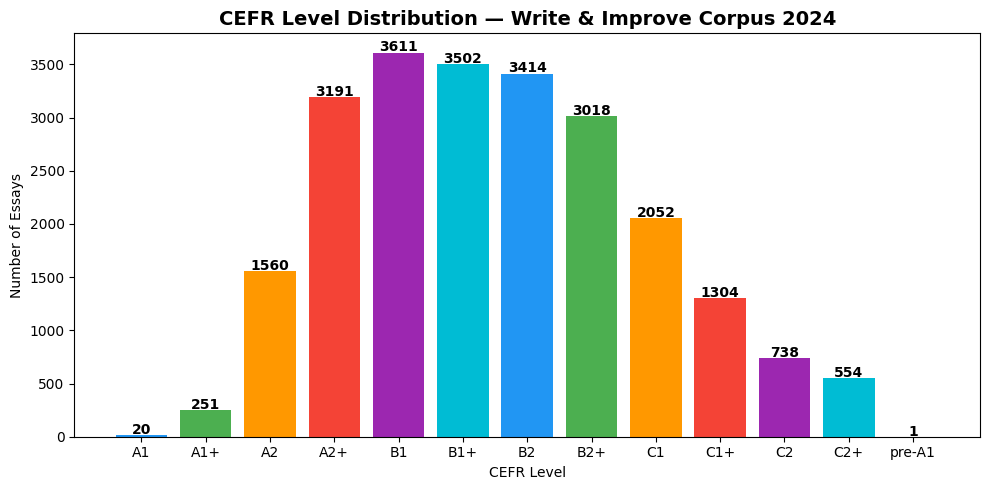


CEFR Distribution:
   A1: 20 (0.1%)
   A1+: 251 (1.1%)
   A2: 1560 (6.7%)
   A2+: 3191 (13.7%)
   B1: 3611 (15.6%)
   B1+: 3502 (15.1%)
   B2: 3414 (14.7%)
   B2+: 3018 (13.0%)
   C1: 2052 (8.8%)
   C1+: 1304 (5.6%)
   C2: 738 (3.2%)
   C2+: 554 (2.4%)
   pre-A1: 1 (0.0%)


In [5]:
# Find CEFR column
cefr_col = [col for col in df_meta.columns if 'cefr' in col.lower()]
print(f'CEFR-related columns found: {cefr_col}')

if cefr_col:
    cefr_counts = df_meta[cefr_col[0]].value_counts().sort_index()

    plt.figure(figsize=(10, 5))
    colors = ['#2196F3', '#4CAF50', '#FF9800', '#F44336', '#9C27B0', '#00BCD4']
    bars = plt.bar(cefr_counts.index, cefr_counts.values, color=colors[:len(cefr_counts)])

    plt.title('CEFR Level Distribution — Write & Improve Corpus 2024',
              fontsize=14, fontweight='bold')
    plt.xlabel('CEFR Level')
    plt.ylabel('Number of Essays')

    for bar, val in zip(bars, cefr_counts.values):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                 str(val), ha='center', fontweight='bold')

    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'cefr_distribution.png'), dpi=150)
    plt.show()

    print(f'\nCEFR Distribution:')
    for level, count in cefr_counts.items():
        pct = count / len(df_meta) * 100
        print(f'   {level}: {count} ({pct:.1f}%)')
else:
    print('⚠️  No CEFR column found — check column names in Cell 3')

---
### Cell 6 — Load Prompts Info

In [6]:
prompts_path = os.path.join(WHOLE_CORPUS_DIR, 'en-writeandimprove2024-prompts-info.tsv')
df_prompts = pd.read_csv(prompts_path, sep='\t')

print(f'✅ Prompts info loaded')
print(f'   Total prompts: {len(df_prompts)}')
print(f'\nColumns: {list(df_prompts.columns)}')
print(f'\nSample prompts:')
print(df_prompts.head())

✅ Prompts info loaded
   Total prompts: 50

Columns: ['question_id', 'public_prompt_id', 'n.essay.sets', 'n.essays', 'topic', 'genre', 'min_words', 'max_words', 'prompt_level', 'prompt']

Sample prompts:
                            question_id         public_prompt_id  \
0  5c066194-0290-4acf-adc8-e92259f75abc  prompt_7fb0941f7b739572   
1  5d554291-d9ac-4055-b583-976169946301  prompt_91626718bd3e657e   
2  5d553a27-c049-4cd6-9dbf-3adfa863c647  prompt_e4c497f7613dcf8a   
3  5e6fb2b2-ae3e-43a7-8240-30f9626b19ec  prompt_029cb9051e09e186   
4  5aeaca1c-3183-42ca-8202-6e08d96654c3  prompt_6e0152cf70e42a3a   

   n.essay.sets  n.essays                      topic  \
0           104       542  Birthdays in your country   
1           104       432          A new school year   
2           103       513          A new school year   
3           103       497       about your free time   
4           103       492                    A party   

                                     genre  min_wo

---
### Cell 7 — Inspect Available Files in Final Versions Directory

In [7]:
print('Files in user-prompt-final-versions:')
for f in sorted(os.listdir(FINAL_VERSIONS_DIR)):
    full_path = os.path.join(FINAL_VERSIONS_DIR, f)
    if os.path.isfile(full_path):
        size = os.path.getsize(full_path)
        print(f'   {f:<50} ({size/1024:.1f} KB)')
    else:
        print(f'   📁 {f}/')

Files in user-prompt-final-versions:
   en-writeandimprove2024-final-versions-dev-essays.conll (833.2 KB)
   en-writeandimprove2024-final-versions-dev-essays.m2 (826.0 KB)
   en-writeandimprove2024-final-versions-dev-sentences.conll (771.1 KB)
   en-writeandimprove2024-final-versions-dev-sentences.corr (423.0 KB)
   en-writeandimprove2024-final-versions-dev-sentences.ids (97.8 KB)
   en-writeandimprove2024-final-versions-dev-sentences.m2 (895.1 KB)
   en-writeandimprove2024-final-versions-dev-sentences.orig (419.2 KB)
   en-writeandimprove2024-final-versions-m2-essay-info.tsv (617.8 KB)
   en-writeandimprove2024-final-versions-m2-sentence-info.tsv (11388.4 KB)
   en-writeandimprove2024-final-versions-orig-dev.md  (438.1 KB)
   en-writeandimprove2024-final-versions-orig-dev.tmp (428.6 KB)
   en-writeandimprove2024-final-versions-orig-test.md (463.1 KB)
   en-writeandimprove2024-final-versions-orig-test.tmp (454.0 KB)
   en-writeandimprove2024-final-versions-orig-train.md (3374.6 KB)
   

---
### Cell 8 — Load Parallel Sentence Pairs
> ⚠️ **Update filenames below** based on what Cell 7 shows you

In [15]:
def load_parallel_file(filepath):
    """Load a plain text file, one sentence per line"""
    with open(filepath, 'r', encoding='utf-8') as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]
    return lines

# ⚠️ Adjust these filenames based on Cell 7 output if needed
orig_path = os.path.join(FINAL_VERSIONS_DIR, 'en-writeandimprove2024-final-versions-train-sentences.orig')
corr_path = os.path.join(FINAL_VERSIONS_DIR, 'en-writeandimprove2024-final-versions-train-sentences.corr')

try:
    orig_sentences = load_parallel_file(orig_path)
    corr_sentences = load_parallel_file(corr_path)

    print(f'✅ Sentence pairs loaded')
    print(f'   Original sentences : {len(orig_sentences)}')
    print(f'   Corrected sentences: {len(corr_sentences)}')
    print(f'\nSample pairs:')
    for i in range(5):
        print(f'\n[{i+1}] ORIGINAL : {orig_sentences[i]}')
        print(f'     CORRECTED: {corr_sentences[i]}')

except FileNotFoundError as e:
    print(f'❌ File not found: {e}')
    print('👉 Update orig_path and corr_path based on Cell 7 output')

✅ Sentence pairs loaded
   Original sentences : 37486
   Corrected sentences: 37486

Sample pairs:

[1] ORIGINAL : New Year is always an invite to establish goals for the next 365 days.
     CORRECTED: A new year is always an invitation to establish goals for the next 365 days.

[2] ORIGINAL : There are some areas there I'm pleased like improving my idioms knowledge, writing, speaking, presenting scientific articles.
     CORRECTED: There are some areas that I'm pleased with, like my knowledge of languages, writing, speaking, and presenting scientific articles.

[3] ORIGINAL : There are also areas that I should improve like statistics, IA, algorithms and how to present a work I developed.
     CORRECTED: There are also areas that I should improve, like statistics, AI, algorithms, and how to present a project I have developed.

[4] ORIGINAL : So I need to have some strategies for achieving goals.
     CORRECTED: So I need to have some strategies for achieving goals.

[5] ORIGINAL : 1 - 

---
### Cell 9 — Find M2 Files

In [16]:
print('Looking for .m2 files in corpus...')
m2_files_found = []

for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        if f.endswith('.m2'):
            full_path = os.path.join(root, f)
            size = os.path.getsize(full_path)
            m2_files_found.append(full_path)
            print(f'   ✅ {full_path} ({size/1024:.1f} KB)')

if not m2_files_found:
    print('❌ No .m2 files found — check your folder structure')

Looking for .m2 files in corpus...
   ✅ C:/gecrag\data/write_and_improve\multigec-2025-files\en-writeandimprove2024-ref1-dev.m2 (779.5 KB)
   ✅ C:/gecrag\data/write_and_improve\multigec-2025-files\local_eval\ref\en-writeandimprove2024-ref1-dev.m2 (779.5 KB)
   ✅ C:/gecrag\data/write_and_improve\user-prompt-final-versions\en-writeandimprove2024-final-versions-dev-essays.m2 (826.0 KB)
   ✅ C:/gecrag\data/write_and_improve\user-prompt-final-versions\en-writeandimprove2024-final-versions-dev-sentences.m2 (895.1 KB)
   ✅ C:/gecrag\data/write_and_improve\user-prompt-final-versions\en-writeandimprove2024-final-versions-train-essays.m2 (6347.4 KB)
   ✅ C:/gecrag\data/write_and_improve\user-prompt-final-versions\en-writeandimprove2024-final-versions-train-sentences.m2 (7010.6 KB)
   ✅ C:/gecrag\data/write_and_improve\user-prompt-first-versions\en-writeandimprove2024-first-versions-dev-essays.m2 (969.8 KB)
   ✅ C:/gecrag\data/write_and_improve\user-prompt-first-versions\en-writeandimprove2024-fi

---
### Cell 10 — Parse M2 File & Extract Error Types

In [17]:
def parse_m2_file(m2_path):
    """
    Parse an M2 file and extract:
    - All error types
    - Original and corrected sentence pairs
    """
    error_types = []
    sentences   = []
    current_orig = None
    current_edits = []

    with open(m2_path, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()

            if line.startswith('S '):
                # Save previous sentence block
                if current_orig is not None:
                    sentences.append({
                        'original': current_orig,
                        'edits': current_edits
                    })
                current_orig  = line[2:]  # Remove 'S '
                current_edits = []

            elif line.startswith('A '):
                parts = line.split('|||')
                if len(parts) >= 3:
                    error_type   = parts[1].strip()
                    correction   = parts[2].strip()
                    if error_type != 'noop':
                        error_types.append(error_type)
                        current_edits.append({
                            'type': error_type,
                            'correction': correction
                        })

        # Don't forget last sentence
        if current_orig is not None:
            sentences.append({
                'original': current_orig,
                'edits': current_edits
            })

    return error_types, sentences


# Use the first m2 file found (preferably train or dev)
# ⚠️ Update this path based on Cell 9 output
m2_path = m2_files_found[0] if m2_files_found else None

if m2_path:
    print(f'Parsing: {m2_path}')
    error_types, sentences = parse_m2_file(m2_path)
    error_counts = Counter(error_types)

    print(f'\n✅ M2 file parsed successfully')
    print(f'   Total sentences parsed : {len(sentences)}')
    print(f'   Total error instances  : {len(error_types)}')
    print(f'   Unique error types     : {len(error_counts)}')
else:
    print('❌ No M2 file available — check Cell 9')

Parsing: C:/gecrag\data/write_and_improve\multigec-2025-files\en-writeandimprove2024-ref1-dev.m2

✅ M2 file parsed successfully
   Total sentences parsed : 506
   Total error instances  : 7100
   Unique error types     : 15


---
### Cell 11 — Error Type Distribution Plot

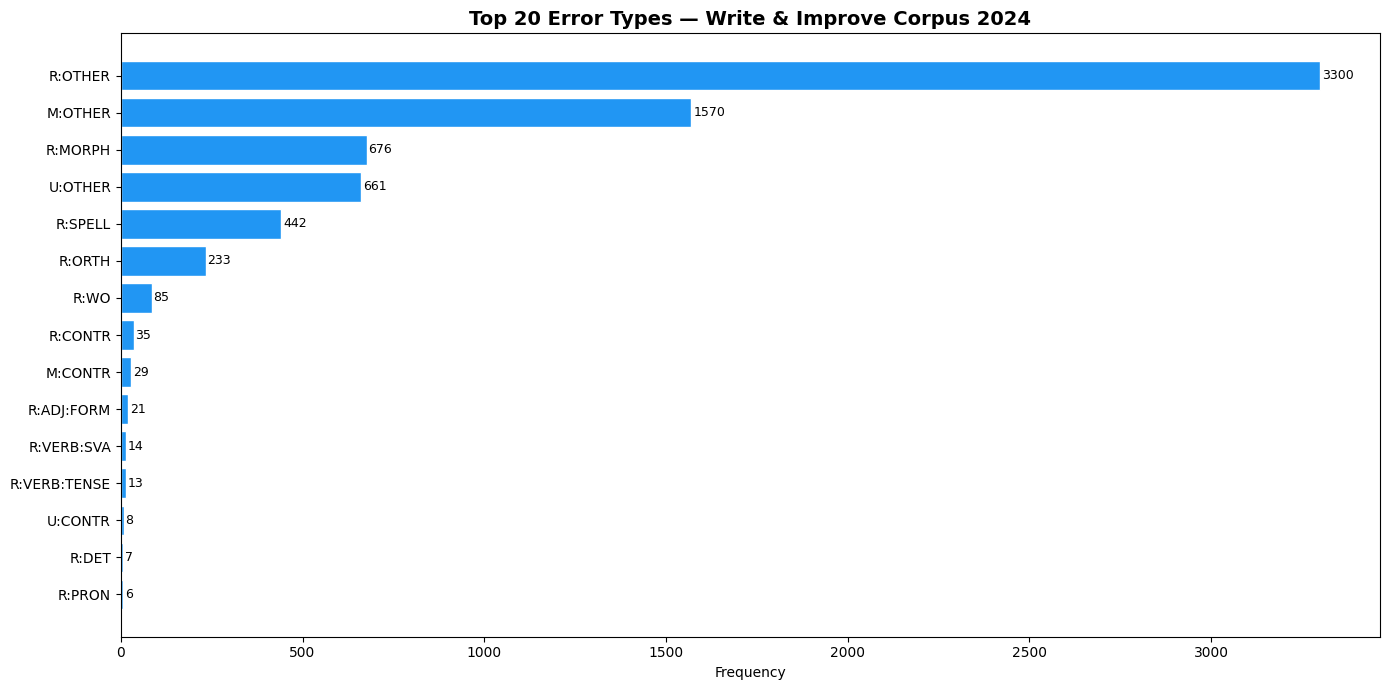


Top 20 Error Types:
Error Type                   Count   % of Total
-----------------------------------------------
R:OTHER                       3300        46.5%
M:OTHER                       1570        22.1%
R:MORPH                        676         9.5%
U:OTHER                        661         9.3%
R:SPELL                        442         6.2%
R:ORTH                         233         3.3%
R:WO                            85         1.2%
R:CONTR                         35         0.5%
M:CONTR                         29         0.4%
R:ADJ:FORM                      21         0.3%
R:VERB:SVA                      14         0.2%
R:VERB:TENSE                    13         0.2%
U:CONTR                          8         0.1%
R:DET                            7         0.1%
R:PRON                           6         0.1%


In [18]:
top_n = 20
top_errors = error_counts.most_common(top_n)
labels, values = zip(*top_errors)

plt.figure(figsize=(14, 7))
bars = plt.barh(labels[::-1], values[::-1], color='#2196F3', edgecolor='white')

# Add value labels
for bar, val in zip(bars, values[::-1]):
    plt.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
             str(val), va='center', fontsize=9)

plt.title(f'Top {top_n} Error Types — Write & Improve Corpus 2024',
          fontsize=14, fontweight='bold')
plt.xlabel('Frequency')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'error_type_distribution.png'), dpi=150)
plt.show()

print(f'\nTop {top_n} Error Types:')
print(f'{"Error Type":<25} {"Count":>8} {"% of Total":>12}')
print('-' * 47)
total = len(error_types)
for err_type, count in top_errors:
    pct = count / total * 100
    print(f'{err_type:<25} {count:>8} {pct:>11.1f}%')

---
### Cell 12 — Error Category Analysis (for RAG KB planning)

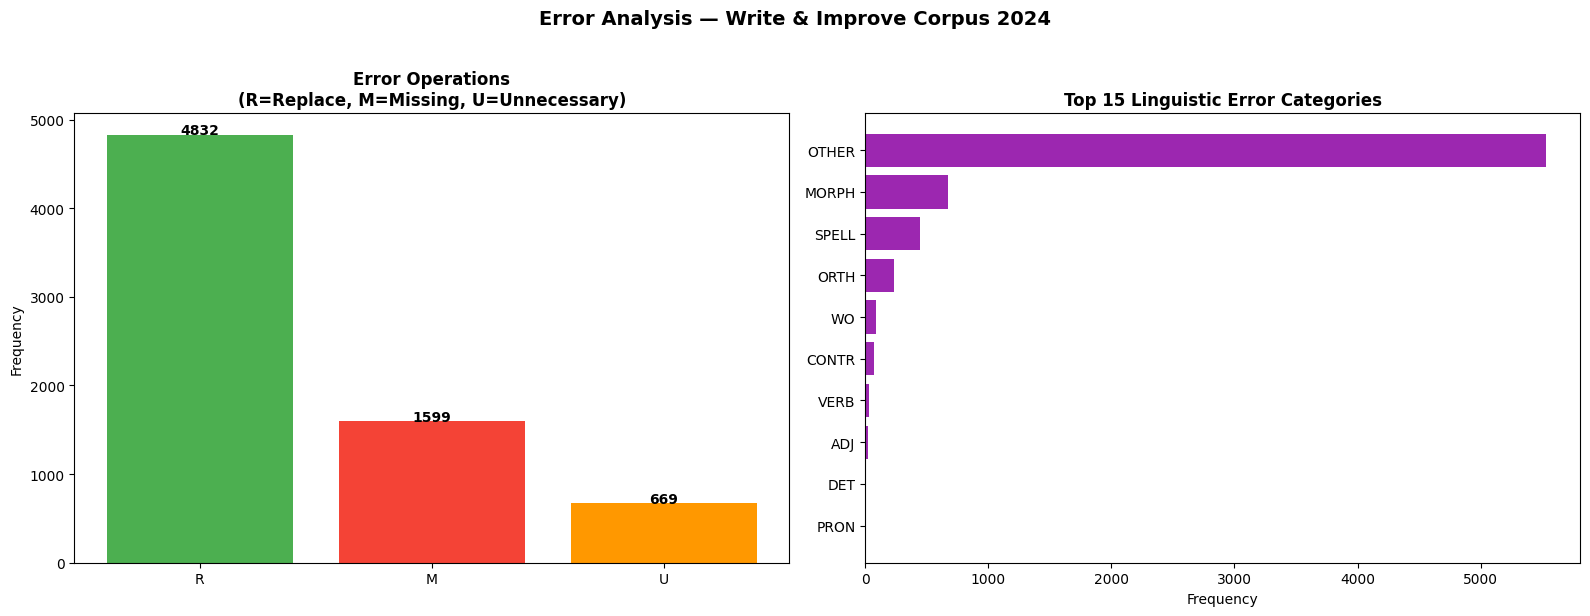


Top Linguistic Categories (relevant for RAG Knowledge Base):
Category                Count   % of Total
------------------------------------------
OTHER                    5531        77.9%
MORPH                     676         9.5%
SPELL                     442         6.2%
ORTH                      233         3.3%
WO                         85         1.2%
CONTR                      72         1.0%
VERB                       27         0.4%
ADJ                        21         0.3%
DET                         7         0.1%
PRON                        6         0.1%


In [19]:
# Group error types into broader categories
# ERRANT format: OPERATION:CATEGORY (e.g. R:VERB:TENSE, M:ART, U:PREP)

def get_operation(error_type):
    """Extract operation: R=Replace, M=Missing, U=Unnecessary"""
    parts = error_type.split(':')
    return parts[0] if parts else 'OTHER'

def get_category(error_type):
    """Extract main linguistic category"""
    parts = error_type.split(':')
    return parts[1] if len(parts) > 1 else 'OTHER'

# Analyze operations
operations = Counter([get_operation(e) for e in error_types])
categories = Counter([get_category(e) for e in error_types])

# Plot side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Operations
op_labels, op_vals = zip(*operations.most_common())
ax1.bar(op_labels, op_vals, color=['#4CAF50', '#F44336', '#FF9800', '#9E9E9E'])
ax1.set_title('Error Operations\n(R=Replace, M=Missing, U=Unnecessary)',
              fontweight='bold')
ax1.set_ylabel('Frequency')
for i, (label, val) in enumerate(zip(op_labels, op_vals)):
    ax1.text(i, val + 5, str(val), ha='center', fontweight='bold')

# Categories — top 15
top_cats = categories.most_common(15)
cat_labels, cat_vals = zip(*top_cats)
ax2.barh(cat_labels[::-1], cat_vals[::-1], color='#9C27B0')
ax2.set_title('Top 15 Linguistic Error Categories', fontweight='bold')
ax2.set_xlabel('Frequency')

plt.suptitle('Error Analysis — Write & Improve Corpus 2024',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'error_category_analysis.png'),
            dpi=150, bbox_inches='tight')
plt.show()

print('\nTop Linguistic Categories (relevant for RAG Knowledge Base):')
print(f'{"Category":<20} {"Count":>8} {"% of Total":>12}')
print('-' * 42)
for cat, count in categories.most_common(15):
    pct = count / total * 100
    print(f'{cat:<20} {count:>8} {pct:>11.1f}%')

---
### Cell 13 — Sentence Length Analysis

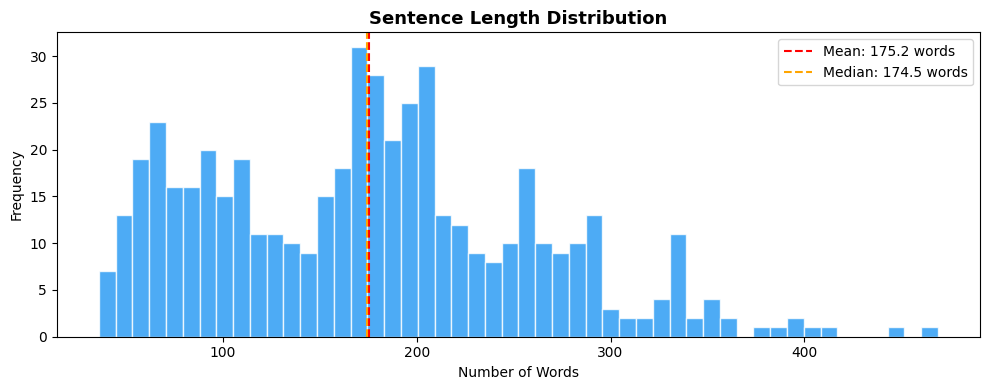

Sentence Length Statistics:
   Mean   : 175.2 words
   Median : 174.5 words
   Min    : 36 words
   Max    : 469 words
   Std    : 83.8 words


In [20]:
# Analyze sentence lengths — useful for model input planning
orig_lengths = [len(s['original'].split()) for s in sentences]

plt.figure(figsize=(10, 4))
plt.hist(orig_lengths, bins=50, color='#2196F3', edgecolor='white', alpha=0.8)
plt.axvline(np.mean(orig_lengths), color='red', linestyle='--',
            label=f'Mean: {np.mean(orig_lengths):.1f} words')
plt.axvline(np.median(orig_lengths), color='orange', linestyle='--',
            label=f'Median: {np.median(orig_lengths):.1f} words')
plt.title('Sentence Length Distribution', fontsize=13, fontweight='bold')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'sentence_length_distribution.png'), dpi=150)
plt.show()

print(f'Sentence Length Statistics:')
print(f'   Mean   : {np.mean(orig_lengths):.1f} words')
print(f'   Median : {np.median(orig_lengths):.1f} words')
print(f'   Min    : {np.min(orig_lengths)} words')
print(f'   Max    : {np.max(orig_lengths)} words')
print(f'   Std    : {np.std(orig_lengths):.1f} words')

---
### Cell 14 — Export Summary for Paper

In [21]:
# Save key statistics to CSV for easy reference when writing the paper

# Error type stats
error_df = pd.DataFrame(error_counts.most_common(), columns=['error_type', 'count'])
error_df['percentage'] = (error_df['count'] / error_df['count'].sum() * 100).round(2)
error_df['operation']  = error_df['error_type'].apply(get_operation)
error_df['category']   = error_df['error_type'].apply(get_category)
error_df.to_csv(os.path.join(RESULTS_DIR, 'error_type_stats.csv'), index=False)

# CEFR stats
if cefr_col:
    cefr_df = df_meta[cefr_col[0]].value_counts().sort_index().reset_index()
    cefr_df.columns = ['cefr_level', 'count']
    cefr_df['percentage'] = (cefr_df['count'] / cefr_df['count'].sum() * 100).round(2)
    cefr_df.to_csv(os.path.join(RESULTS_DIR, 'cefr_stats.csv'), index=False)

print('=' * 55)
print('CORPUS SUMMARY — WRITE & IMPROVE 2024')
print('=' * 55)
print(f'\n📊 Dataset Size:')
print(f'   Total essays in metadata : {len(df_meta)}')
print(f'   Total sentences (m2 file): {len(sentences)}')

if cefr_col:
    print(f'\n📊 CEFR Distribution:')
    for _, row in cefr_df.iterrows():
        print(f'   {row["cefr_level"]}: {row["count"]} ({row["percentage"]}%)')

print(f'\n📊 Error Analysis:')
print(f'   Total error instances : {len(error_types)}')
print(f'   Unique error types    : {len(error_counts)}')
print(f'   Most common error     : {error_counts.most_common(1)[0][0]} '
      f'({error_counts.most_common(1)[0][1]} instances)')

print(f'\n📊 Sentence Lengths:')
print(f'   Mean   : {np.mean(orig_lengths):.1f} words')
print(f'   Median : {np.median(orig_lengths):.1f} words')

print(f'\n✅ All results saved to: {RESULTS_DIR}')
print(f'   - error_type_stats.csv')
print(f'   - cefr_stats.csv')
print(f'   - cefr_distribution.png')
print(f'   - error_type_distribution.png')
print(f'   - error_category_analysis.png')
print(f'   - sentence_length_distribution.png')
print(f'\n➡️  Next: Run Notebook 02 — ERRANT Annotation Pipeline')

CORPUS SUMMARY — WRITE & IMPROVE 2024

📊 Dataset Size:
   Total essays in metadata : 23216
   Total sentences (m2 file): 506

📊 CEFR Distribution:
   A1: 20 (0.09%)
   A1+: 251 (1.08%)
   A2: 1560 (6.72%)
   A2+: 3191 (13.74%)
   B1: 3611 (15.55%)
   B1+: 3502 (15.08%)
   B2: 3414 (14.71%)
   B2+: 3018 (13.0%)
   C1: 2052 (8.84%)
   C1+: 1304 (5.62%)
   C2: 738 (3.18%)
   C2+: 554 (2.39%)
   pre-A1: 1 (0.0%)

📊 Error Analysis:
   Total error instances : 7100
   Unique error types    : 15
   Most common error     : R:OTHER (3300 instances)

📊 Sentence Lengths:
   Mean   : 175.2 words
   Median : 174.5 words

✅ All results saved to: C:/gecrag\results
   - error_type_stats.csv
   - cefr_stats.csv
   - cefr_distribution.png
   - error_type_distribution.png
   - error_category_analysis.png
   - sentence_length_distribution.png

➡️  Next: Run Notebook 02 — ERRANT Annotation Pipeline
